# IMDB Movie Review Classification

In [23]:
from keras.models import Sequential, load_model
from keras.layers import Dense, LSTM, Embedding, Dropout
from keras.datasets import imdb
from keras.utils import pad_sequences
import matplotlib.pyplot as plt

In [2]:
# Step-1: Load the data with top 5000 words only
top_words = 7000 #5000
(X_train, y_train), (X_test, y_test) = imdb.load_data(num_words=top_words)

In [3]:
X_train.shape, X_test.shape

((25000,), (25000,))

In [4]:
y_test

array([0, 1, 1, ..., 0, 0, 0])

In [5]:
len(X_train[0]), len(X_train[1]), len(X_train[2]), len(X_train[3])

(218, 189, 141, 550)

In [6]:
# X_train[0]

In [7]:
word_index = imdb.get_word_index()
# word_index

In [8]:
reverse_word_index = dict([(value, key) for (key, value) in word_index.items()])
# reverse_word_index

In [9]:
review_index = 0
decoded_review = ' '.join([reverse_word_index.get(i-3, '?') for i in X_train[review_index]])
print(decoded_review)

? this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert ? is an amazing actor and now the same being director ? father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for ? and would recommend it to everyone to watch and the fly fishing was amazing really cried at the end it was so sad and you know what they say if you cry at a film it must have been good and this definitely was also ? to the two little boy's that played the ? of norman and paul they were just brilliant children are often left out of the ? list i think because the stars that play them all grown up are such a big ? for the whole film but these children are amazing and should be praised for what they have done don't you think the

In [10]:
y_train[review_index]

np.int64(1)

In [11]:
# Step-2: Align the review length
max_review_length = 400 #500
X_train = pad_sequences(X_train, maxlen=max_review_length)
X_test = pad_sequences(X_test, maxlen=max_review_length)

In [12]:
len(X_train[0]), len(X_train[1]), len(X_train[2]), len(X_train[3])

(400, 400, 400, 400)

In [13]:
# X_train[0]

In [14]:
# Step-3: Embadding for words
embedding_vector_length = 64 #32

In [15]:
# Model
model = Sequential()
model.add(Embedding(top_words, embedding_vector_length, input_length=max_review_length))

model.add(LSTM(100))
model.add(Dropout(0.4))
model.add(Dense(1, activation='sigmoid'))


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [16]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [17]:
# Compile
model.compile('adam', 'binary_crossentropy', metrics=['accuracy'])

In [18]:
# Callbacks
from keras.callbacks import EarlyStopping, ModelCheckpoint

# EarlyStopping
es = EarlyStopping(monitor='val_accuracy',
                   patience=10,
                   verbose=1,
                   mode='max')

# ModelCheckpoint
mc = ModelCheckpoint(filepath='best_model.keras',
                     monitor='val_accuracy',
                     verbose=1,
                     save_best_only=True,
                     mode='max')

In [19]:
# Train
history = model.fit(X_train,
                    y_train,
                    epochs=10,
                    batch_size=64,
                    validation_split=0.2,
                    verbose=True,
                    callbacks=[es, mc])

Epoch 1/10
312/313 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.6881 - loss: 0.5588
Epoch 1: val_accuracy improved from None to 0.62640, saving model to best_model.keras

Epoch 1: finished saving model to best_model.keras
313/313 ━━━━━━━━━━━━━━━━━━━━ 13s 22ms/step - accuracy: 0.7581 - loss: 0.4906 - val_accuracy: 0.6264 - val_loss: 0.6883
Epoch 2/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.7944 - loss: 0.4243
Epoch 2: val_accuracy improved from 0.62640 to 0.81780, saving model to best_model.keras

Epoch 2: finished saving model to best_model.keras
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step - accuracy: 0.8474 - loss: 0.3489 - val_accuracy: 0.8178 - val_loss: 0.4096
Epoch 3/10
312/313 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.8977 - loss: 0.2637
Epoch 3: val_accuracy did not improve from 0.81780
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - accuracy: 0.8967 - loss: 0.2628 - val_accuracy: 0.8130 - val_loss: 0.4140
Epoch 4/10
311/313 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step -

In [20]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 400, 64)        │       448,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 100)            │        66,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │           101 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,542,305 (5.88 MB)

 Trainable params: 514,101 (1.96 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,028,204 (3.92 MB)

In [21]:
model.evaluate(X_test, y_test)

782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.8458 - loss: 0.4947


[0.4946545958518982, 0.8457599878311157]

In [24]:
# Load best model and evaluate
best_model = load_model('best_model.keras')
best_model.evaluate(X_test, y_test)

782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.8624 - loss: 0.4248


[0.4248110055923462, 0.8623999953269958]

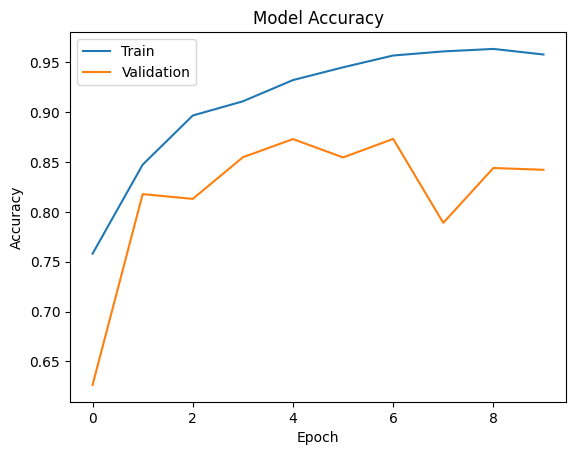

In [25]:
# Visualization
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')

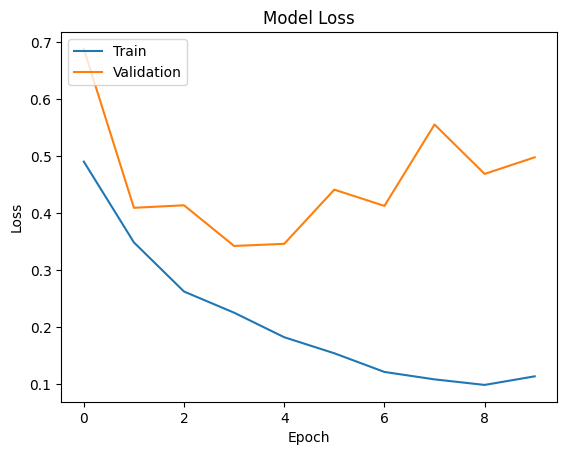

In [26]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
#